# Research Experiment 03 — Volatility Asymmetry and Market-Regime Detection

**Research portfolio:** Ezekiel Apima Onchong’a  
**Repository:** `apimaezekiel-arch/regime-aware-option-pricing`  
**Companion:** `02_garch_volatility_forecasting.ipynb`  
**Status:** Reproducible research template; **no empirical conclusions have been precomputed**.

**Research questions**
1. Does a negative return shock produce a larger conditional volatility response than an equally sized positive shock?
2. Do asymmetric GJR-GARCH and EGARCH models improve one-day-ahead variance forecasts relative to symmetric GARCH(1,1)?
3. Does the relative performance vary across **ex-ante** low, medium and high volatility regimes?

This study uses historical **SPY adjusted daily closes**, **not option quotes**; conclusions concern *return-variance forecasts*, not option-pricing accuracy. Educational research, not investment advice.

## 1 · Install packages

Use **Runtime → Run all** in Google Colab. Internet is required for installation and price downloads. Results will vary with data provider revisions and settings.

In [1]:
%pip -q install "yfinance>=0.2.50" "arch>=7.0" "numpy>=1.24" "pandas>=2.0" "matplotlib>=3.7" "scipy>=1.10"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 7.8 MB/s eta 0:00:00


In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from arch import arch_model
from IPython.display import display

plt.rcParams.update({'figure.figsize': (11, 4.8), 'axes.grid': True})
SEED = 971951
np.random.seed(SEED)
print('pandas', pd.__version__, 'numpy', np.__version__)

pandas 2.2.3 numpy 2.1.3


## 2 · Historical SPY observations

We maintain the **same calendar window as Experiment 02**: January 2020 to December 2025 (end exclusive). One daily log-return observation is lost when differencing. Missing / duplicated prices are checked explicitly. The forecast target is **squared percent log-return** (a noisy proxy for unobserved conditional variance).

In [3]:
TICKER = 'SPY'
START, END = '2020-01-01', '2026-01-01'  # yfinance end is exclusive
TEST_DAYS = 120
WINDOW = 750  # rolling past observations
REFIT_EVERY = 10
REGIME_LOOKBACK = 21
EPS = 1e-10

raw = yf.download(TICKER, start=START, end=END, auto_adjust=True, progress=False)
if raw.empty:
    raise RuntimeError('SPY download returned no data; check internet access and date range.')
close = raw['Close']
if isinstance(close, pd.DataFrame):
    close = close[TICKER] if TICKER in close.columns else close.iloc[:, 0]
close = pd.to_numeric(close, errors='coerce').dropna().sort_index()
close = close[~close.index.duplicated(keep='last')]
assert len(close) > WINDOW + TEST_DAYS + REGIME_LOOKBACK, 'Not enough observations.'
assert (close > 0).all(), 'Prices must be positive.'
returns = (100 * np.log(close / close.shift(1))).dropna().rename('return_pct')
print(f'Price observations: {len(close)}, return observations: {len(returns)}')
print('Range:', returns.index.min().date(), 'to', returns.index.max().date())
display(returns.describe().to_frame('daily return (%)'))

Price observations: 1508, return observations: 1507
Range: 2020-01-03 to 2025-12-31


,daily return (%)
count,1507.000000
mean,0.054999
std,1.310055
min,-11.588650
25%,-0.485639
50%,0.097197
75%,0.681099
max,9.986284


## 3 · Visualize volatility clustering and a descriptive asymmetry signal

The scatterplot is **descriptive**, not a causal or statistically definitive leverage-effect test. A formal asymmetric-volatility parameter will be examined later.

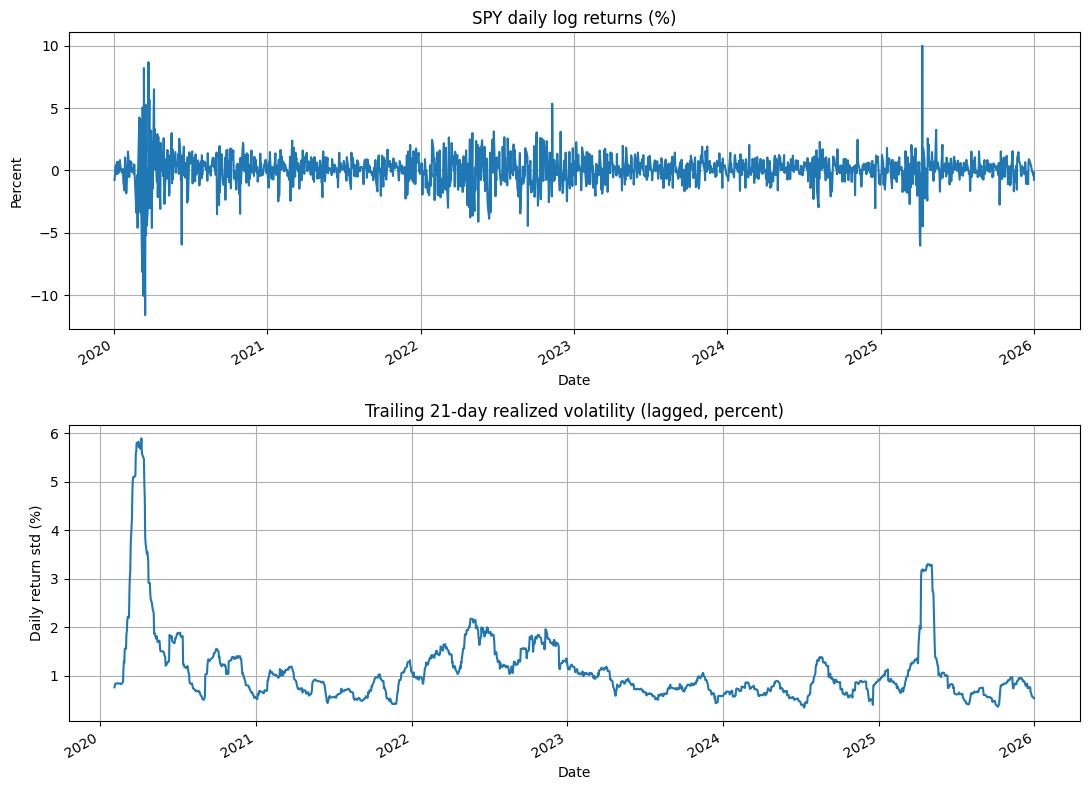

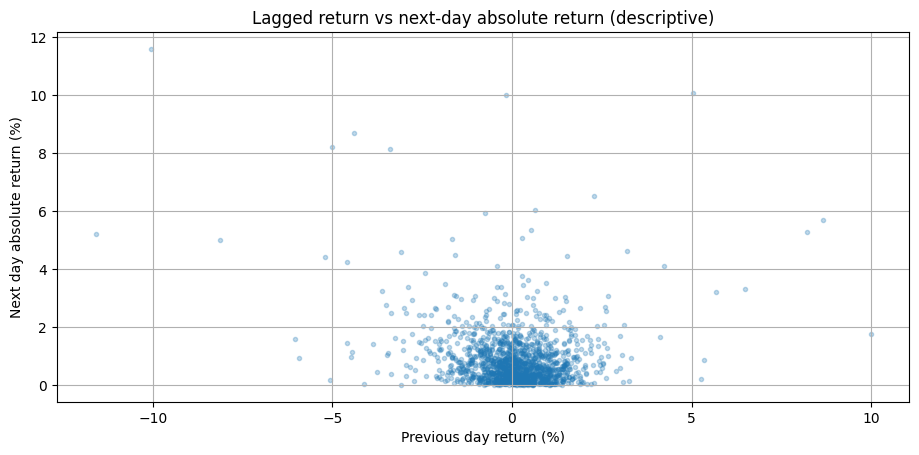

In [4]:
fig, axs = plt.subplots(2, 1, figsize=(11, 8))
returns.plot(ax=axs[0], title='SPY daily log returns (%)')
axs[0].set_ylabel('Percent')
rv21 = returns.rolling(REGIME_LOOKBACK).std().shift(1)  # only prior observations
rv21.plot(ax=axs[1], title='Trailing 21-day realized volatility (lagged, percent)')
axs[1].set_ylabel('Daily return std (%)')
plt.tight_layout(); plt.show()

x = returns.shift(1).dropna()
y = returns.abs().reindex(x.index).shift(-1).dropna()
common = x.index.intersection(y.index)
fig, ax = plt.subplots()
ax.scatter(x.loc[common], y.loc[common], s=9, alpha=.28)
ax.set(xlabel='Previous day return (%)', ylabel='Next day absolute return (%)',
       title='Lagged return vs next-day absolute return (descriptive)')
plt.show()

## 4 · Modeling framework and asymmetry

In **percent-return units**, innovations are assumed to have zero conditional mean and a normal conditional distribution in this baseline. The three conditional variance models are:

**Symmetric GARCH(1,1):**
\[h_t=\omega+\alpha\epsilon_{t-1}^2+\beta h_{t-1}.\]

**GJR-GARCH(1,1,1):**
\[h_t=\omega+\alpha\epsilon_{t-1}^2+\gamma\mathbf{1}(\epsilon_{t-1}<0)\epsilon_{t-1}^2+\beta h_{t-1}.\]
When \(\gamma>0\), negative shocks amplify the variance response *holding shock magnitude constant*. Statistical inference is required.

**EGARCH(1,1,1):**
\[\log h_t=\omega+\alpha(|z_{t-1}|-\sqrt{2/\pi})+\gamma z_{t-1}+\beta\log h_{t-1},\quad z_t=\epsilon_t/\sqrt{h_t}.\]
For EGARCH, **negative** \(\gamma\) represents stronger responses to negative standardized shocks. These signs refer to the `arch` parametrization.

**Caution:** These are conditional variance specifications, not full identification of a causal leverage effect. Normal innovations are a starting point; Student-t robustness can follow.

In [5]:
MODELS = {
    'GARCH': dict(vol='GARCH', p=1, o=0, q=1),
    'GJR-GARCH': dict(vol='GARCH', p=1, o=1, q=1),
    'EGARCH': dict(vol='EGARCH', p=1, o=1, q=1),
}

def estimate_model(history, name):
    """Fit on ONLY the past rolling window. Mean zero; variance in percent^2."""
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', category=RuntimeWarning)
        fit = arch_model(np.asarray(history, dtype=float), mean='Zero',
                         dist='normal', rescale=False, **MODELS[name]).fit(
                            disp='off', show_warning=False)
    par = fit.params.to_dict()
    if not np.isfinite(np.asarray(list(par.values()), dtype=float)).all():
        raise RuntimeError(f'Nonfinite parameters for {name}')
    last_h = float(fit.conditional_volatility[-1] ** 2)
    if not np.isfinite(last_h) or last_h <= 0:
        raise RuntimeError(f'Invalid last variance for {name}')
    return fit, par, last_h

def advance_one(name, par, last_return, last_h):
    """Return h_t from prior residual and prior conditional variance h_(t-1)."""
    a = par['alpha[1]']; beta = par['beta[1]']; omega = par['omega']
    if name == 'GARCH':
        h = omega + a * last_return**2 + beta * last_h
    elif name == 'GJR-GARCH':
        g = par['gamma[1]']
        h = omega + (a + g * (last_return < 0)) * last_return**2 + beta * last_h
    else:
        g = par['gamma[1]']
        z = last_return / np.sqrt(max(last_h, EPS))
        h = np.exp(np.clip(omega + a * (abs(z) - np.sqrt(2 / np.pi))
                           + g*z + beta * np.log(max(last_h, EPS)), -30, 30))
    return float(max(h, EPS))

# Fit an illustrative model on the pre-test training window only.
train_example = returns.iloc[-TEST_DAYS-WINDOW:-TEST_DAYS]
fits = {name: estimate_model(train_example, name) for name in MODELS}
parameter_table = pd.DataFrame({name: output[1] for name, output in fits.items()}).T
print('Initial training-window estimates (not full-sample or out-of-sample results):')
display(parameter_table)
for name in ('GJR-GARCH','EGARCH'):
    fit, pars, _ = fits[name]
    print(f'{name}: gamma={pars.get("gamma[1]"):.5f}, p-value={fit.pvalues.get("gamma[1]", float("nan")):.4g}')

Initial training-window estimates (not full-sample or out-of-sample results):


,omega,alpha[1],beta[1],gamma[1]
GARCH,0.031828,0.103409,0.868182,NaN
GJR-GARCH,0.032271,0.000000,0.880554,0.194530
EGARCH,0.006651,0.093119,0.960067,-0.174772


GJR-GARCH: gamma=0.19453, p-value=0.0003536
EGARCH: gamma=-0.17477, p-value=1.096e-05


## 5 · Chronological forecast experiment (no look-ahead)

At the start of each 10-day block, parameters are re-estimated using the **750 most recent returns available at that time**. Each day's forecast uses the previous observed return and previous model variance. After observing a new daily return, the next forecast is updated — the forecast for day *t* never uses return *t*.

Ex-ante regime thresholds (33rd and 67th percentiles) are estimated from lagged 21-day realized volatility **within the original training sample only**, then held fixed. The daily regime label uses volatility through *t−1* exclusively. This avoids conditioning on future realized volatility. Regime assignments are descriptive and may have imbalanced test samples.

In [6]:
test_start = len(returns) - TEST_DAYS
training_regime_proxy = rv21.iloc[:test_start].dropna()
qlo, qhi = training_regime_proxy.quantile([1/3, 2/3])
assert qlo < qhi, 'Regime cutoffs need distinct values.'

def regime_of(v):
    if pd.isna(v): return 'Unknown'
    return 'Low' if v <= qlo else ('High' if v > qhi else 'Medium')

records = []
for block_start in range(test_start, len(returns), REFIT_EVERY):
    prior = returns.iloc[block_start-WINDOW:block_start]
    assert len(prior) == WINDOW
    state = {}
    for name in MODELS:
        fit, p, last_h = estimate_model(prior, name)
        state[name] = [p, last_h]
    for j in range(block_start, min(block_start+REFIT_EVERY, len(returns))):
        previous_return = float(returns.iloc[j-1])
        observation = float(returns.iloc[j])
        out = {'date': returns.index[j], 'observed_pct': observation,
               'proxy_variance': observation**2,
               'lagged_21d_vol': rv21.iloc[j],
               'regime': regime_of(rv21.iloc[j])}
        for name in MODELS:
            parameters, previous_h = state[name]
            h_next = advance_one(name, parameters, previous_return, previous_h)
            out[name] = h_next
            state[name][1] = h_next
        records.append(out)

pred = pd.DataFrame(records).set_index('date')
assert len(pred) == TEST_DAYS
assert (pred[list(MODELS)] > 0).all().all()
assert pred[list(MODELS)].notna().all().all()
print(f'Test period: {pred.index.min().date()} to {pred.index.max().date()}')
print('Training-only regime thresholds (% daily volatility):',round(qlo,4),round(qhi,4))
print('Test sample by regime:')
display(pred['regime'].value_counts().to_frame('days'))
display(pred.head())

Test period: 2025-07-14 to 2025-12-31
Training-only regime thresholds (% daily volatility): 0.7626 1.1651
Test sample by regime:


,days
regime,
Low,78
Medium,42


,observed_pct,proxy_variance,lagged_21d_vol,regime,GARCH,GJR-GARCH,EGARCH
date,,,,,,,
2025-07-14,0.190654,0.036349,0.622946,Low,0.486358,0.426409,0.411847
2025-07-15,-0.428248,0.183397,0.613999,Low,0.457833,0.407747,0.389230
2025-07-16,0.333765,0.111399,0.626789,Low,0.448275,0.426990,0.453997
2025-07-17,0.610092,0.372213,0.554335,Low,0.432532,0.408259,0.420536
2025-07-18,-0.073255,0.005366,0.537047,Low,0.445834,0.391764,0.376777


## 6 · Compare out-of-sample errors

The squared daily return \(r_t^2\) is a very noisy proxy for latent variance \(h_t\). We report variance MSE and **QLIKE**, defined as \(\log h_t + r_t^2/h_t\) (lower is better). A negative mean QLIKE is possible because its additive constant is omitted.

Regime-specific rankings are exploratory. Very small regime samples are labeled and **should not support strong conclusions**; a longer out-of-sample history or formal loss-differential inference is required.

In [7]:
def metrics(df, name):
    proxy = df['proxy_variance'].to_numpy(dtype=float)
    h = df[name].to_numpy(dtype=float)
    return {'n_days':len(df), 'variance_MSE':float(np.mean((proxy-h)**2)),
            'QLIKE':float(np.mean(np.log(h) + proxy/h))}

scores = pd.DataFrame({name: metrics(pred, name) for name in MODELS}).T
print('Full held-out test:')
display(scores.sort_values('QLIKE'))
rows = []
for regime in ('Low','Medium','High'):
    subset = pred[pred.regime == regime]
    if subset.empty: continue
    for name in MODELS:
        rows.append({'regime':regime, 'model':name, **metrics(subset, name)})
by_regime = pd.DataFrame(rows)
print('Forecast performance by ex-ante volatility regime:')
display(by_regime.sort_values(['regime','QLIKE']))
if any(by_regime.groupby('regime')['n_days'].first() < 20):
    print('CAUTION: At least one regime has fewer than 20 observations; comparisons are descriptive.')

Full held-out test:


,n_days,variance_MSE,QLIKE
EGARCH,120.0,0.803587,0.258222
GJR-GARCH,120.0,0.839705,0.288054
GARCH,120.0,0.848636,0.328409


Forecast performance by ex-ante volatility regime:


,regime,model,n_days,variance_MSE,QLIKE
2,Low,EGARCH,78,0.985655,0.172281
1,Low,GJR-GARCH,78,0.971205,0.196436
0,Low,GARCH,78,1.025153,0.264906
5,Medium,EGARCH,42,0.465461,0.417826
3,Medium,GARCH,42,0.520819,0.446344
4,Medium,GJR-GARCH,42,0.595490,0.458202


## 7 · Graphical evidence and controlled shock response

The shock-response comparison holds prior variance fixed at its last estimated value and compares one hypothetical positive versus negative shock. This is a *model-implied response*, not an empirical causal estimate.

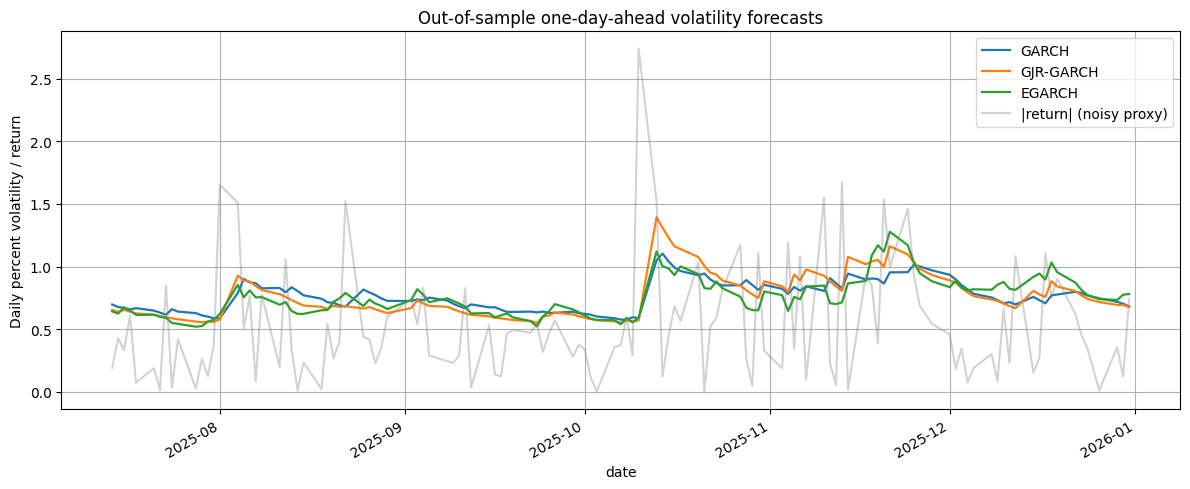

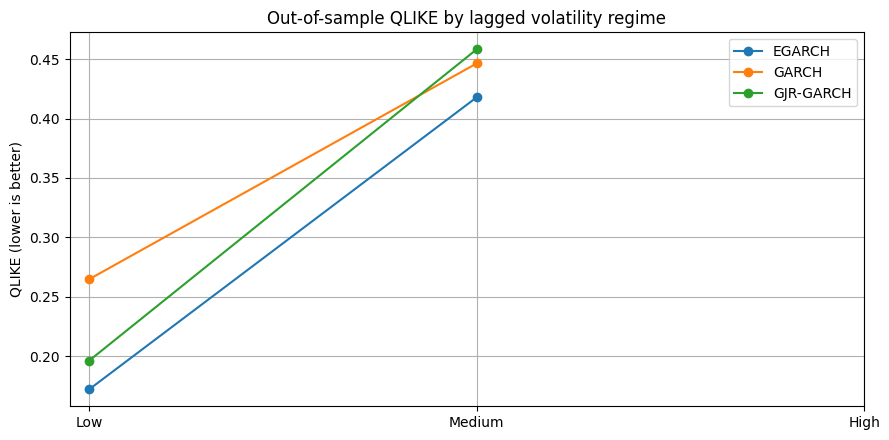

,model,shock_pct,next_variance
0,GARCH,-2.0,0.887170
1,GARCH,2.0,0.887170
2,GJR-GARCH,-2.0,1.180405
3,GJR-GARCH,2.0,0.402284
4,EGARCH,-2.0,0.858042
5,EGARCH,2.0,0.268339


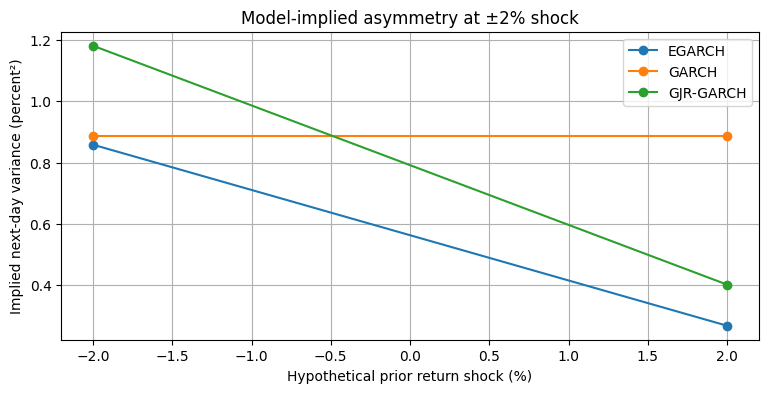

In [8]:
fig, ax = plt.subplots(figsize=(12,5))
for name in MODELS:
    np.sqrt(pred[name]).plot(ax=ax, label=name, lw=1.6)
pred['observed_pct'].abs().plot(ax=ax, color='gray', alpha=.35, label='|return| (noisy proxy)')
ax.set(ylabel='Daily percent volatility / return',
       title='Out-of-sample one-day-ahead volatility forecasts')
ax.legend(); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9,4.5))
for name, part in by_regime.groupby('model'):
    ax.plot(part['regime'].map({'Low':0,'Medium':1,'High':2}),part['QLIKE'],
            marker='o',label=name)
ax.set_xticks([0,1,2], ['Low','Medium','High'])
ax.set(title='Out-of-sample QLIKE by lagged volatility regime', ylabel='QLIKE (lower is better)')
ax.legend(); plt.tight_layout(); plt.show()

shock_magnitude = 2.0  # 2% daily log return, hypothetical
response = []
for name in MODELS:
    _, p, last_h = fits[name]
    for shock in (-shock_magnitude, shock_magnitude):
        response.append({'model':name,'shock_pct':shock,
                         'next_variance':advance_one(name,p,shock,last_h)})
shock_table = pd.DataFrame(response)
display(shock_table)
fig, ax = plt.subplots(figsize=(9,4))
for name, group in shock_table.groupby('model'):
    ax.plot(group['shock_pct'], group['next_variance'],marker='o',label=name)
ax.set(xlabel='Hypothetical prior return shock (%)',ylabel='Implied next-day variance (percent²)',
       title='Model-implied asymmetry at ±2% shock')
ax.legend();plt.show()

## 8 · Diagnostics and interpretation checklist

- Check convergence diagnostics, estimated parameters, standard errors and stationarity conditions. The fitted asymmetric terms alone do **not** prove a robust leverage effect.
- Compare rankings under both loss functions; discordant rankings are possible.
- Inspect the number of holdout observations per regime before making claims.
- Extend to several independent test periods, heavy-tailed innovations, and bootstrap / Diebold–Mariano-style loss differential tests (with attention to serial correlation) before reporting statistical superiority.
- Volatility forecasts are not options-pricing errors. A later experiment must obtain actual option quotes with timestamps, moneyness, and maturity to test pricing performance.

**Reproducibility note:** `yfinance` data may change; save data retrieval dates and package versions. Do not publish proprietary third-party options data without permission.

In [9]:
out = Path('results')
out.mkdir(exist_ok=True)
pred.to_csv(out/'spy_asymmetric_volatility_predictions.csv')
scores.to_csv(out/'spy_asymmetric_volatility_scores.csv')
by_regime.to_csv(out/'spy_regime_model_scores.csv', index=False)
parameter_table.to_csv(out/'spy_initial_asymmetric_parameters.csv')
shock_table.to_csv(out/'spy_model_shock_response.csv', index=False)
print('Saved five CSV files to',out.resolve())
print('Next: inspect forecasts, document limitations, and upload notebook to GitHub.')

Saved five CSV files to /content/results
Next: inspect forecasts, document limitations, and upload notebook to GitHub.
